# Power Plant Energy Output Prediction

Estimate a power plant’s electrical energy output from operating and weather measurements. The input columns are Ambient Temperature (°C), Exhaust Vacuum (cm Hg), Ambient Pressure (mbar), and Relative Humidity (%); the target is Electrical Output (MW). The original short column names are converted to these descriptive names just after loading the CSV.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [51]:
df = pd.read_csv('powerplant.csv')
df = df.rename(columns={
    'AT': 'Ambient Temperature (°C)',
    'V': 'Exhaust Vacuum (cm Hg)',
    'AP': 'Ambient Pressure (mbar)',
    'RH': 'Relative Humidity (%)',
    'PE': 'Electrical Output (MW)',
})

In [52]:
df.shape

(9568, 5)

In [53]:
df.head()

,Ambient Temperature (°C),Exhaust Vacuum (cm Hg),Ambient Pressure (mbar),Relative Humidity (%),Electrical Output (MW)
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


In [31]:
df.describe()

,Ambient Temperature (°C),Exhaust Vacuum (cm Hg),Ambient Pressure (mbar),Relative Humidity (%),Electrical Output (MW)
count,9568.000000,9568.000000,9568.000000,9568.000000,9568.000000
mean,19.651231,54.305804,1013.259078,73.308978,454.365009
std,7.452473,12.707893,5.938784,14.600269,17.066995
min,1.810000,25.360000,992.890000,25.560000,420.260000
25%,13.510000,41.740000,1009.100000,63.327500,439.750000
50%,20.345000,52.080000,1012.940000,74.975000,451.550000
75%,25.720000,66.540000,1017.260000,84.830000,468.430000
max,37.110000,81.560000,1033.300000,100.160000,495.760000


In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9568 entries, 0 to 9567
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Ambient Temperature (°C)  9568 non-null   float64
 1   Exhaust Vacuum (cm Hg)    9568 non-null   float64
 2   Ambient Pressure (mbar)   9568 non-null   float64
 3   Relative Humidity (%)     9568 non-null   float64
 4   Electrical Output (MW)    9568 non-null   float64
dtypes: float64(5)
memory usage: 373.9 KB


In [34]:
df.isnull().sum()

Ambient Temperature (°C)    0
Exhaust Vacuum (cm Hg)      0
Ambient Pressure (mbar)     0
Relative Humidity (%)       0
Electrical Output (MW)      0
dtype: int64

## Exploratory Data Analysis

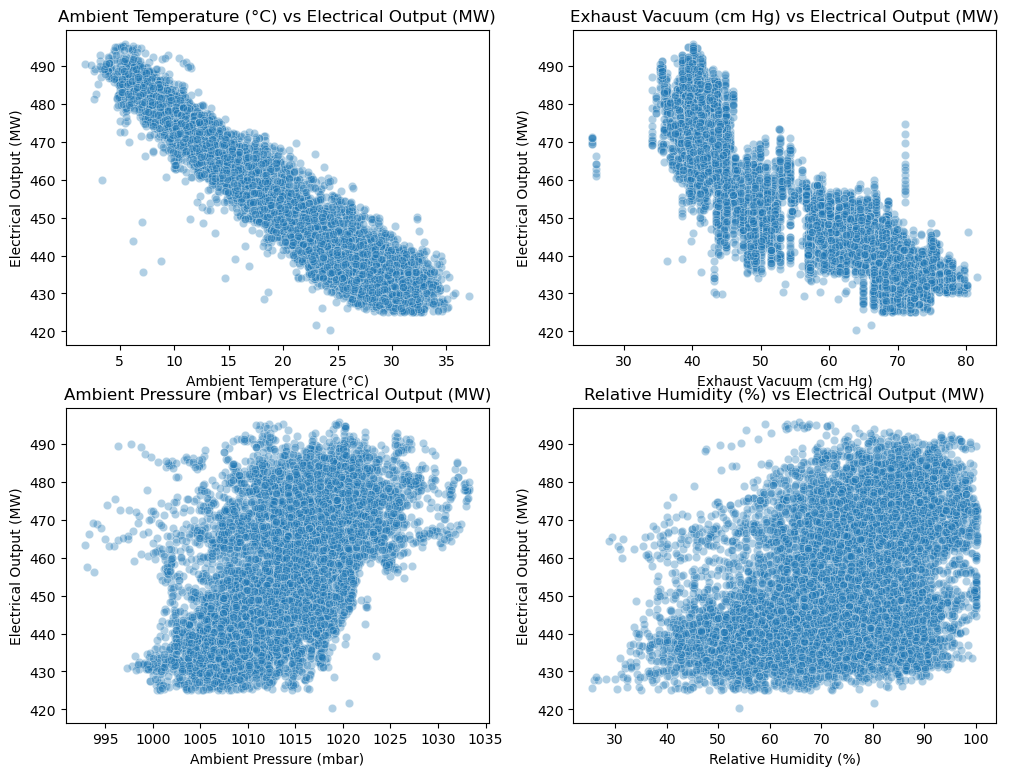

In [61]:
features = ['Ambient Temperature (°C)', 'Exhaust Vacuum (cm Hg)', 'Ambient Pressure (mbar)', 'Relative Humidity (%)']
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for feature, ax in zip(features, axes.flat):
    sns.scatterplot(data=df, x=feature, y='Electrical Output (MW)', alpha=0.35, ax=ax)
    ax.set_title(f'{feature} vs Electrical Output (MW)')
plt.show()

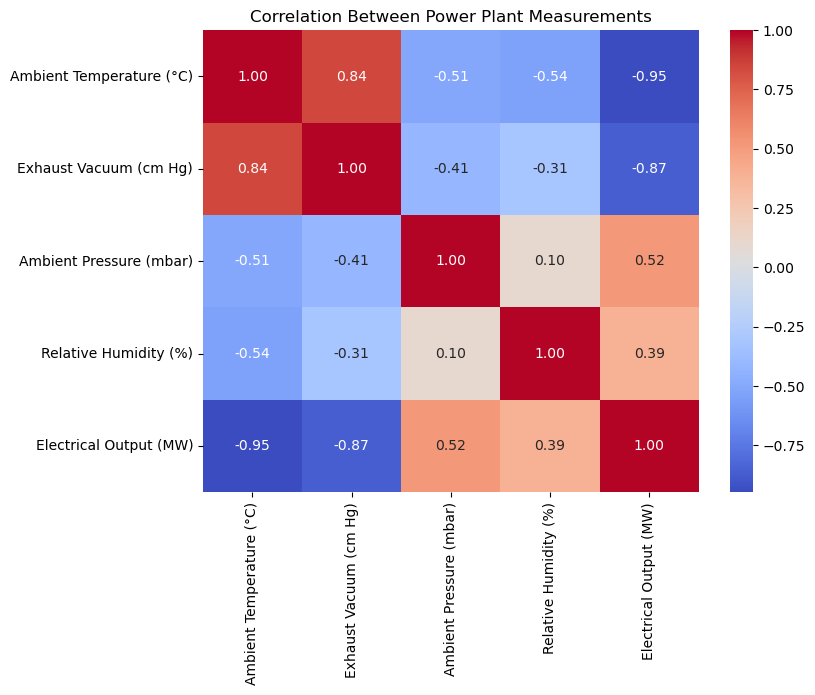

In [66]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Between Power Plant Measurements')
plt.show()

## Prepare Data and Compare Models

Use the four measurements as features and `Electrical Output (MW)` as the value to predict. A held-out test set is reserved for the final model comparison.

In [38]:
X = df[['Ambient Temperature (°C)', 'Exhaust Vacuum (cm Hg)', 'Ambient Pressure (mbar)', 'Relative Humidity (%)']]
y = df['Electrical Output (MW)']

In [39]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

In [40]:
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree Regressor': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'Support Vector': SVR()
}

In [41]:
def evaluate_model(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    return mae, mse, rmse, r2, y_pred

In [42]:
model_performance = {}
predictions = {}

In [43]:
for name, model in models.items():
    mae, mse, rmse, r2, y_pred = evaluate_model(
        model, X_train, y_train, X_test, y_test
    )
    model_performance[name] = {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2}
    predictions[name] = y_pred

In [70]:
performance_df = pd.DataFrame(model_performance).T
performance_df

,MAE,MSE,RMSE,R2
Linear Regression,3.649933,21.239857,4.608672,0.927548
Decision Tree Regressor,3.114699,20.431549,4.520127,0.930306
Random Forest,2.392194,11.220838,3.349752,0.961724
Gradient Boosting,2.988782,15.492219,3.936016,0.947154
Support Vector,11.592860,191.653006,13.843880,0.346250


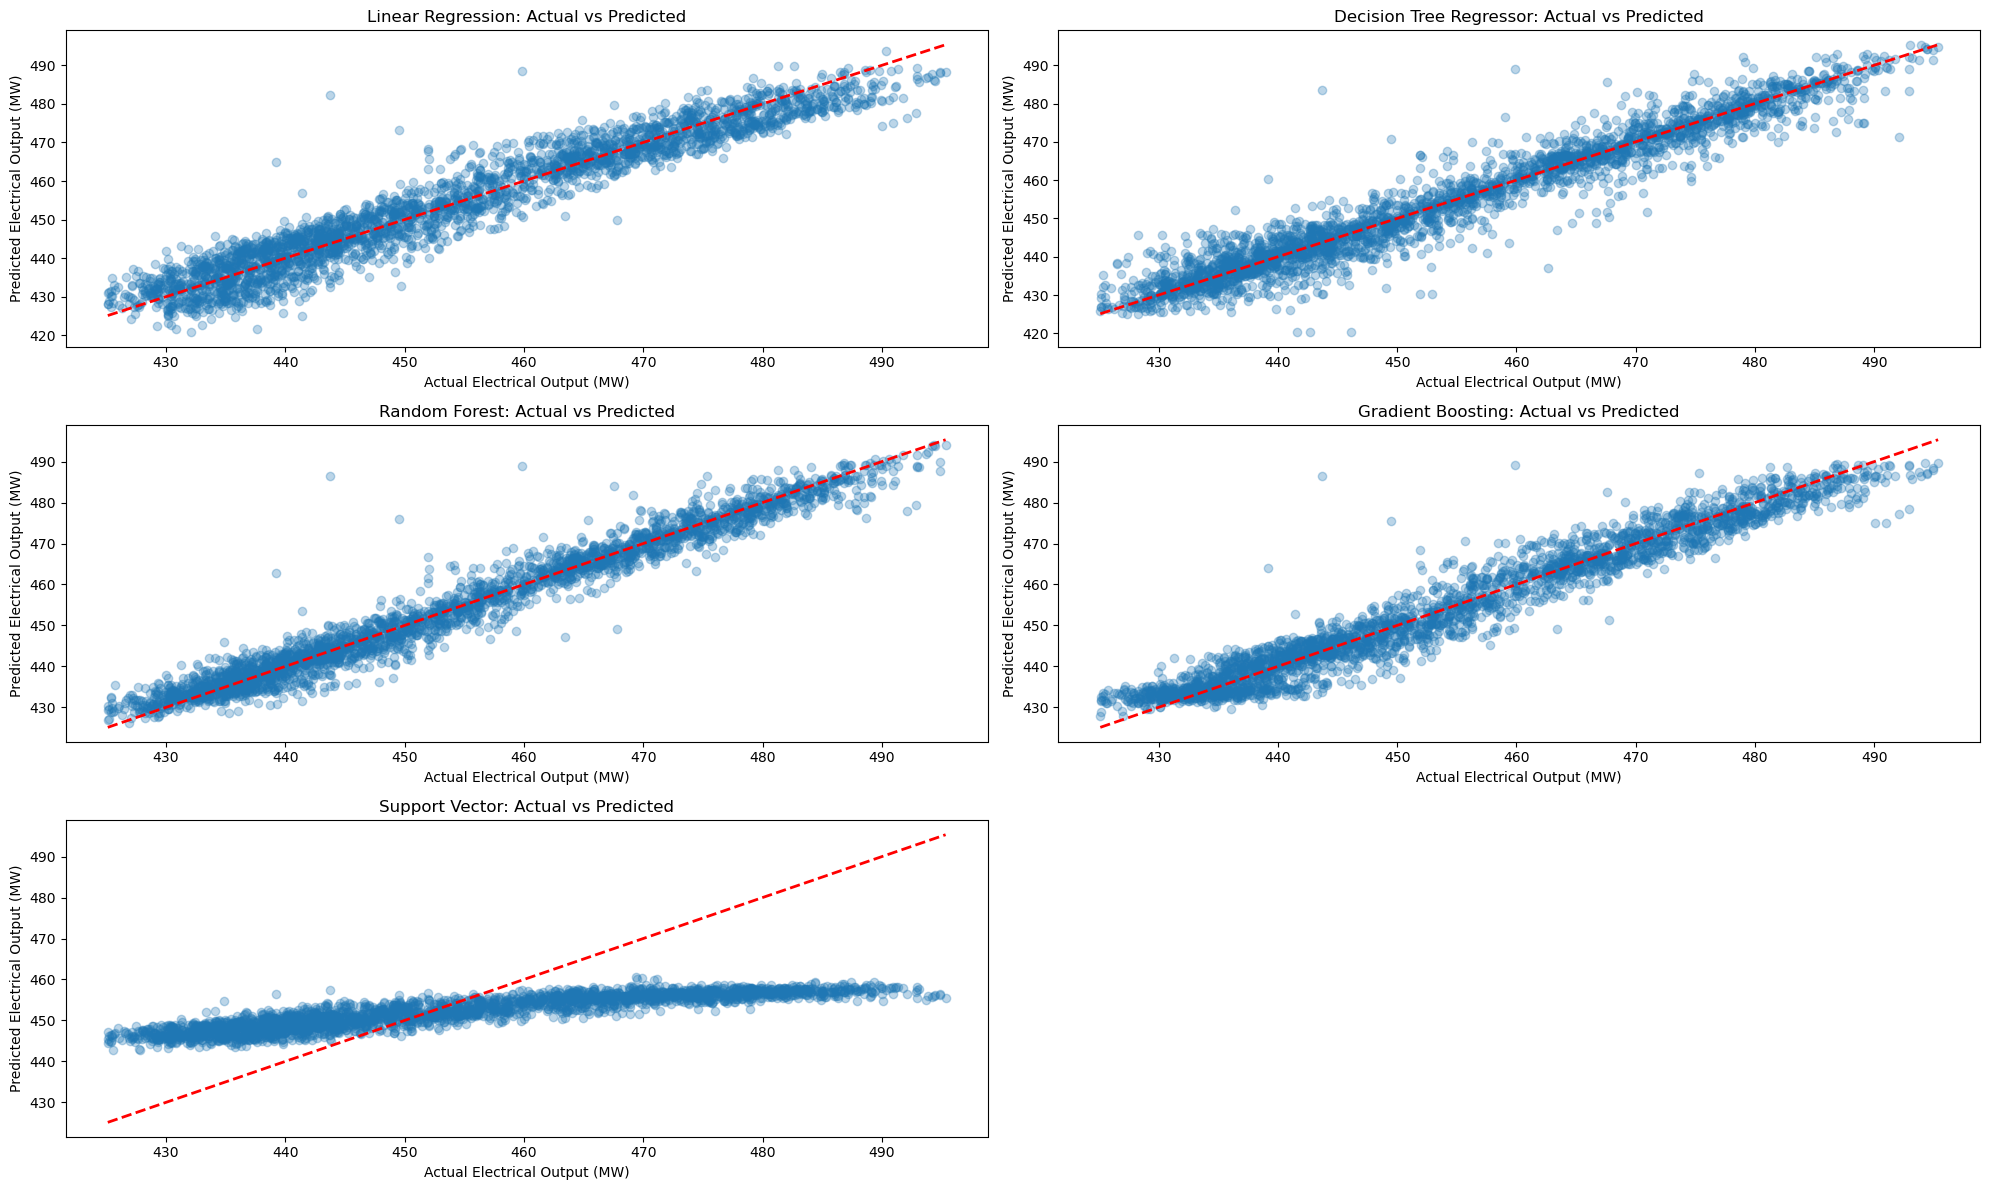

In [72]:
plt.figure(figsize=(20, 12))
for i, (name, preds) in enumerate(predictions.items(), 1):
    plt.subplot(3, 2, i)
    plt.scatter(y_test, preds, alpha=0.3)
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--r', linewidth=2)
    plt.title(f'{name}: Actual vs Predicted')
    plt.xlabel('Actual Electrical Output (MW)')
    plt.ylabel('Predicted Electrical Output (MW)')
plt.tight_layout()
plt.show()

In [46]:
best_model_name = performance_df['R2'].idxmax()
print('Best Performing Model:', best_model_name)
print(performance_df.loc[best_model_name])

Best Performing Model: Random Forest
MAE      2.392194
MSE     11.220838
RMSE     3.349752
R2       0.961724
Name: Random Forest, dtype: float64
